# ITE 17 – Data Mining
## Midterm Summative Activity
### Philippine Educational System — Social Media Discourse Analysis

---



In [ ]:
# Install packages not included by default in Google Colab
import subprocess
import sys

for package in ['gensim', 'wordcloud']:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', package, '-q'])

print('Colab dependencies installed: gensim, wordcloud')

Colab dependencies installed: gensim, wordcloud


## Setup - Import Libraries

In [ ]:
import os
import pandas as pd
import numpy as np
import re
import math
import warnings
from collections import Counter
warnings.filterwarnings('ignore')
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
# Inline plots for Jupyter / Google Colab
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    pass

import matplotlib.pyplot as plt
import seaborn as sns

try:
    from wordcloud import WordCloud
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'wordcloud', '-q'])
    from wordcloud import WordCloud

import nltk
from nltk.util import ngrams
for _nltk_resource in ['punkt', 'punkt_tab']:
    try:
        nltk.download(_nltk_resource, quiet=True)
    except Exception:
        pass

from nltk.stem import WordNetLemmatizer
import nltk

try:
    from gensim import corpora, models
    from gensim.models import CoherenceModel
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'gensim', '-q'])
    from gensim import corpora, models
    from gensim.models import CoherenceModel

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances, manhattan_distances
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    try:
        plt.style.use('seaborn-whitegrid')
    except OSError:
        pass

print('All libraries loaded successfully.')

All libraries loaded successfully.


## Load Dataset

In [ ]:
import os
import pandas as pd

# Works in Google Colab (upload), Google Drive, and local Jupyter
CANDIDATE_PATHS = [
    'Data Mining Scrape - Fixed Dataset.csv',
    '/content/Data Mining Scrape - Fixed Dataset.csv',
    '/content/drive/MyDrive/Data Mining Scrape - Fixed Dataset.csv',
]

DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if DATA_PATH is None:
    try:
        from google.colab import files
        print('Dataset not found. Please upload your CSV file:')
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            'Dataset not found. Place "Data Mining Scrape - Fixed Dataset.csv" '
            'in the notebook folder or upload it in Colab.'
        )

print(f'Loading dataset from: {DATA_PATH}')
df_raw = pd.read_csv(DATA_PATH)


# Select the existing columns with their correct names from df_raw
df = df_raw[['Comment_Author', 'Comment_Text', 'Title', 'datetime', 'Query','Social Media Source']].copy()


# Rename the columns to the standardized names for the notebook
df.columns = ['author', 'comment', 'title', 'datetime', 'query', 'source']

# Clean records
df['comment'] = df['comment'].astype(str).str.strip()
df = df[df['comment'].notna() & (df['comment'] != '') & (df['comment'] != '[deleted]')].copy()
df['source'] = df['source'].astype(str).str.lower().str.strip()
df['source'] = df['source'].replace({'nan': 'unknown'})
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df['comment_len'] = df['comment'].str.len()
df['word_count'] = df['comment'].str.split().str.len()

print(f'Dataset loaded: {len(df)} records')
df.head(3)

Loading dataset from: Data Mining Scrape - Fixed Dataset.csv
Dataset loaded: 970 records


,author,comment,title,datetime,query,source,comment_len,word_count
0,pauljpjohn,This is more practical than 1k per student all...,Kiko files free breakfast program bill for K-1...,2025-07-03 18:16:48,Eudcation Philippines,reddit,119,21
1,purple_lass,"Right? Parang sa Japan at S.Korea, may free me...",Kiko files free breakfast program bill for K-1...,2025-07-03 18:16:48,Eudcation Philippines,reddit,63,11
2,Hpezlin,This would actually encourage people to go to ...,Kiko files free breakfast program bill for K-1...,2025-07-03 18:16:48,Eudcation Philippines,reddit,53,9


---
# PHASE 1 — DATA EXPLORATION

Complete dataset summary, quality checks, text statistics, language distribution, and frequency analysis.

In [ ]:
# 1.1 Dataset summary
summary = {
    'Total Records': len(df),
    'Total Comments': df['comment'].notna().sum(),
    'Date Range Start': df['datetime'].min(),
    'Date Range End': df['datetime'].max(),
    'Exact Duplicate Rows': int(df.duplicated().sum()),
    'Near-Duplicate Comments (same text)': int(df['comment'].duplicated().sum()),
}
print('=' * 55)
print('DATASET SUMMARY')
print('=' * 55)
for k, v in summary.items():
    print(f'  {k}: {v}')

print('\nPlatform Distribution:')
platform_dist = df['source'].value_counts()
platform_pct = (platform_dist / len(df) * 100).round(2)
platform_table = pd.DataFrame({'Count': platform_dist, 'Percent': platform_pct})
print(platform_table.to_string())


DATASET SUMMARY
  Total Records: 970
  Total Comments: 970
  Date Range Start: 2023-08-14 03:43:22
  Date Range End: 2026-06-17 12:50:32
  Exact Duplicate Rows: 13
  Near-Duplicate Comments (same text): 25

Platform Distribution:
                   Count  Percent
source                           
facebook             407    41.96
reddit               289    29.79
tiktok               230    23.71
youtube               33     3.40
instagram              9     0.93
instagram-hashtag      2     0.21


In [ ]:
# Deduplicate for modeling while keeping audit trail
df_model = df.drop_duplicates(subset=['comment'], keep='first').copy()
print(f'Records after comment-level deduplication: {len(df_model)} (removed {len(df) - len(df_model)})')

# Text statistics per platform
stats = df_model.groupby('source').agg(
    comments=('comment', 'count'),
    avg_chars=('comment_len', 'mean'),
    min_chars=('comment_len', 'min'),
    max_chars=('comment_len', 'max'),
    avg_words=('word_count', 'mean')
).round(1)
print('\nText Statistics per Platform:')
print(stats.to_string())

# Most active threads and contributors
print('\nTop 5 Discussion Threads:')
print(df_model['title'].value_counts().head(5))
print('\nTop 5 Contributors:')
print(df_model['author'].value_counts().head(5))

Records after comment-level deduplication: 945 (removed 25)

Text Statistics per Platform:
                   comments  avg_chars  min_chars  max_chars  avg_words
source                                                                 
facebook                407      166.2          6       4296       27.5
instagram                 9      251.1         27       1129       37.6
instagram-hashtag         2       26.5          4         49        4.0
reddit                  289      307.5         26       4022       51.5
tiktok                  205      144.6         11        846       25.8
youtube                  33      189.1         40        300       32.6

Top 5 Discussion Threads:
title
Nagsimula na ang mga school heads sa mga pampublikong paaralan sa buong bansa ng serye ng orientation bilang paghahanda ng Department of Education (DepEd) sa mga mahahalagang reporma sa pagtuturo at pagkatuto para sa School Year 2026–2027.\n \n Basahin: https://www.deped.gov.ph/2026/04/24/angara-nag

In [ ]:
df_model['post_text'] = df_model['comment'].fillna('') + ' ' + df_model['title'].fillna('')
df_model['post_text'] = df_model['post_text'].str.strip()
print(f"'post_text' column created. Sample: '{df_model['post_text'].iloc[0]}'", )


'post_text' column created. Sample: 'This is more practical than 1k per student allowance. Sana maimplement ng maayos lalo na sa mga di accessible na lugar. Kiko files free breakfast program bill for K-12 public school students'


In [ ]:
import re
# Language distribution heuristic (Tagalog markers vs English markers)
TAGALOG_MARKERS = {'ang','ng','sa','na','mga','hindi','dapat','guro','paaralan','edukasyon','aral','bata','deped'}
ENGLISH_MARKERS = {'the','and','school','education','teacher','student','because','should','government'}

def detect_language_mix(text):
    toks = set(re.findall(r"[a-zA-Z']+", str(text).lower()))
    tl = len(toks & TAGALOG_MARKERS)
    en = len(toks & ENGLISH_MARKERS)
    if tl >= 2 and en >= 2:
        return 'Taglish'
    if tl > en:
        return 'Filipino/Tagalog'
    if en > tl:
        return 'English'
    return 'Mixed/Unclear'

df_model['language_mix'] = df_model['comment'].apply(detect_language_mix)
lang_dist = df_model['language_mix'].value_counts()
lang_pct = (lang_dist / len(df_model) * 100).round(1)
lang_table = pd.DataFrame({'Count': lang_dist, 'Percent': lang_pct})
print('Language Distribution:')
print(lang_table.to_string())

Language Distribution:
                  Count  Percent
language_mix                    
Filipino/Tagalog    490     51.9
English             223     23.6
Mixed/Unclear       142     15.0
Taglish              90      9.5


### 1.2 — Text Preprocessing & Custom Stopword List


In [ ]:
# Download NLTK data
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

all_words = []
for c in df_model['comment']:
    all_words.extend(re.findall(r"[a-zA-Z']+", str(c).lower()))
word_freq = Counter(all_words)


AUTO_STOP = {w for w, c in word_freq.most_common(120)
             if w in {
                 'the','and','for','with','this','that','they','are','was','were','have','has','had',
                 'will','would','could','should','not','no','but','so','if','as','by','from','to','of',
                 'in','on','at','is','it','he','she','we','you','i','a','an','their','them','those',
                 'these','what','who','how','when','where','why','which','our','more','some','very',
                 'all','one','about','up','out','time','there','know','think','need','see','look',
                 'ang','ng','sa','na','ay','at','mga','ko','mo','po','naman','kasi','pero','yung',
                 'ito','iyon','yon','siya','sila','kami','tayo','natin','nila','niya','nya','nyo',
                 'ka','ikaw','kayo','ako','pag','kung','kaya','din','rin','lang','lamang','pa',
                 'nang','dito','doon','saan','sino','ano','bakit','paano','daw','raw','talaga',
                 'dahil','para','upang','nag','mag','maka','ba','eh','oo','hindi','di','wala','may',
                 'mayroon','meron','nung','noong','ngayon','lahat','walang','maraming','sobrang',
                 'medyo','kahit','gaano','ganito','ganyan','ganoon','ganun','siguro','tapos','mas',
                 'dapat','nga','yan','yun','un','ung','pala','sana','man','wag','huwag','lagi',
                 'lalo','nasa','dami','puro','nalang','re','like','just','get','got','can','school',
                 'schools','teacher','teachers','also','education'
             }}

DOMAIN_KEEP = {'student','students','deped',
               'curriculum','grade','college','university','learning','classroom','salary','budget'}
CUSTOM_STOPWORDS = AUTO_STOP - DOMAIN_KEEP

print(f'Custom stopword list size: {len(CUSTOM_STOPWORDS)}')

SLANG_MAP = {
    'fckng': 'frustrated', 'amp': 'angry', 'ddshit': 'criticism', 'waley': 'none',
    'grabe': 'severe', 'sana': 'hope', 'char': 'joking', 'charot': 'joking'
}

EMOJI_MAP = {
    # Positive emojis
    '😊': 'smiling_face', '😃': 'grinning_face', '😄': 'happy_face',
    '😁': 'beaming_face', '😆': 'laughing_face', '🥰': 'loving_face',
    '😍': 'heart_eyes', '🤩': 'star_struck', '😇': 'angel_face',
    '👍': 'thumbs_up', '👏': 'clapping', '🙌': 'raising_hands',
    '💪': 'strong', '🎉': 'celebration', '🎊': 'confetti',
    '✨': 'sparkles', '💯': 'hundred_points', '🔥': 'fire',
    '❤️': 'red_heart', '💖': 'sparkling_heart', '💕': 'two_hearts',
    '🙏': 'folded_hands', '👌': 'ok_hand', '🌟': 'glowing_star',
    '🤗': 'hugging_face', '💐': 'bouquet',
    '🏆': 'trophy', '🥇': 'first_place', '💡': 'idea',

    # Negative emojis
    '😢': 'crying_face', '😭': 'loudly_crying', '😞': 'disappointed',
    '😔': 'pensive', '😟': 'worried', '😕': 'confused',
    '🙁': 'slightly_frowning', '😣': 'persevering', '😖': 'confounded',
    '😫': 'tired_face', '😩': 'weary', '😤': 'huffing',
    '😠': 'angry_face', '😡': 'pouting', '🤬': 'cursing',
    '💔': 'broken_heart', '😱': 'screaming', '😨': 'fearful',
    '😰': 'anxious', '😓': 'downcast', '😥': 'sad_relieved',
    '👎': 'thumbs_down', '🤢': 'nauseated', '🤮': 'vomiting',
    '💩': 'pile_of_poo', '☠️': 'skull_crossbones', '👿': 'angry_devil',
    '😒': 'unamused', '🙄': 'eye_roll', '😑': 'expressionless','😂': 'tears_of_joy',

    # Neutral / informational
    '🤔': 'thinking', '😐': 'neutral', '😶': 'no_mouth',
    '📚': 'books', '🏫': 'school', '👨‍🏫': 'male_teacher',
    '👩‍🏫': 'female_teacher', '👦': 'boy', '👧': 'girl',
    '🎓': 'graduation', '📖': 'open_book', '✏️': 'pencil',
    '🇵🇭': 'philippines', '⚠️': 'warning', '❗': 'exclamation',
    '❓': 'question', '💬': 'speech', '📢': 'loudspeaker',
}

def convert_emojis_to_text(text):
    """Replace emojis with descriptive text tokens before cleaning."""
    text = str(text)
    for emoji, name in EMOJI_MAP.items():
        if emoji in text:
            text = text.replace(emoji, f' {name} ')
    # Remove any remaining emojis (those not in map) silently
    text = re.sub(r'[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF\U0001F680-\U0001F6FF'
                  r'\U0001F1E0-\U0001F1FF\U00002702-\U000027B0\U0001F900-\U0001F9FF'
                  r'\U0001FA00-\U0001FA6F\U0001FA70-\U0001FAFF\U00002600-\U000026FF'
                  r'\U0000FE00-\U0000FE0F\U0000200D]+', ' ', text, flags=re.UNICODE)
    return text
# ============================================================
# LEMMATIZATION SETUP
# ============================================================

# Extended Tagalog lemmatization
TAGALOG_LEMMA = {
    # Verbs
    'nagsabi': 'sabi', 'sinabi': 'sabi', 'sinasabi': 'sabi', 'sasabihin': 'sabi',
    'nagturo': 'turo', 'tinuro': 'turo', 'tinuturo': 'turo', 'ituturo': 'turo',
    'gumawa': 'gawa', 'ginawa': 'gawa', 'ginagawa': 'gawa', 'gagawin': 'gawa',
    'nagbasa': 'basa', 'binasa': 'basa', 'binabasa': 'basa', 'babasahin': 'basa',
    'nagsulat': 'sulat', 'sinulat': 'sulat', 'sinusulat': 'sulat', 'susulatin': 'sulat',
    'nagbigay': 'bigay', 'ibinigay': 'bigay', 'ibibigay': 'bigay',
    'tumulong': 'tulong', 'tumutulong': 'tulong', 'tutulong': 'tulong',
    'nagbayad': 'bayad', 'binayaran': 'bayad', 'magbabayad': 'bayad',
    'kumain': 'kain', 'kumakain': 'kain', 'kakain': 'kain',
    'umalis': 'alis', 'umaalis': 'alis', 'aalis': 'alis',
    'pumunta': 'punta', 'pupunta': 'punta', 'pumupunta': 'punta',
    'tumanggap': 'tanggap', 'tumatanggap': 'tanggap', 'tatanggap': 'tanggap',

    # Adjectives
    'maganda': 'ganda', 'gumanda': 'ganda',
    'mahirap': 'hirap', 'humihirap': 'hirap', 'nagpapahirap': 'hirap',
    'madali': 'dali',
    'mabigat': 'bigat',
    'malaki': 'laki', 'lumaki': 'laki', 'lumalaki': 'laki',
    'maliit': 'liit', 'lumiliit': 'liit',
    'masaya': 'saya', 'nalulungkot': 'lungkot',
    'malungkot': 'lungkot',

    # Nouns/action words
    'pagtuturo': 'turo', 'pagbabasa': 'basa', 'pagsusulat': 'sulat',
    'pag-aaral': 'aral', 'pagpapaaral': 'aral', 'pagsasanay': 'sanay',
    'pagtulong': 'tulong', 'pagbigay': 'bigay', 'pagbayad': 'bayad',

    # Common adverbs
    'talagang': 'talaga', 'napaka': 'sobra', 'kasing': 'parehas',
    'sabay': 'sabay', 'sabay-sabay': 'sabay',
}

def lemmatize_tagalog(token):
    """Lemmatize a Tagalog token using dictionary and pattern matching"""
    token_clean = re.sub(r'[^a-z]', '', str(token).lower())
    if not token_clean:
        return ''

    # Direct match
    if token_clean in TAGALOG_LEMMA:
        return TAGALOG_LEMMA[token_clean]

    # Check for common Tagalog prefixes
    for prefix in ['nagpa', 'magpa', 'pinag', 'pina', 'nag', 'mag', 'pag', 'mak', 'nak', 'kin']:
        if token_clean.startswith(prefix) and len(token_clean) > len(prefix) + 1:
            base = token_clean[len(prefix):]
            if len(base) >= 2:
                if base in TAGALOG_LEMMA.values():
                    return base
                for suffix in ['an', 'han', 'in', 'ng']:
                    if base.endswith(suffix) and len(base) > len(suffix) + 1:
                        stem = base[:-len(suffix)]
                        if len(stem) >= 2:
                            return stem
                return base

    # Check for common Tagalog suffixes
    for suffix in ['um', 'an', 'han', 'in']:
        if token_clean.endswith(suffix) and len(token_clean) > len(suffix) + 1:
            stem = token_clean[:-len(suffix)]
            if len(stem) >= 2:
                if stem in TAGALOG_LEMMA.values():
                    return stem
                return stem

    return token_clean

def lemmatize_token(token):
    """Lemmatize a single token (English or Tagalog)"""
    token_clean = re.sub(r'[^a-z]', '', str(token).lower())
    if not token_clean:
        return ''

    # Check if token is likely Tagalog
    tagalog_patterns = ['ng', 'han', 'mag', 'nag', 'pag', 'mak', 'nak']
    is_tagalog = any(token_clean.startswith(p) or token_clean.endswith(p) for p in tagalog_patterns)

    if is_tagalog:
        return lemmatize_tagalog(token_clean)
    else:
        return lemmatizer.lemmatize(token_clean)

def preprocess_with_lemmatization(text, min_len=3):
    """Full preprocessing pipeline with lemmatization"""
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove special characters (keep letters and spaces)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenize and lemmatize
    tokens = text.split()
    lemmatized = [lemmatize_token(t) for t in tokens]

    # Remove stopwords and short tokens
    final_tokens = [t for t in lemmatized
                   if t
                   and t not in CUSTOM_STOPWORDS
                   and len(t) >= min_len
                   and t.isalpha()]

    return final_tokens


df_model['tokens'] = df_model['post_text'].apply(preprocess_with_lemmatization) # Changed from 'comment' to 'post_text'

print("Sample before preprocessing:")
print(df_model['post_text'].iloc[0]) # Changed from 'comment' to 'post_text'
print("\nAfter preprocessing WITH lemmatization:")
print(df_model['tokens'].iloc[0])


def preprocess_for_sentiment(text):
    t = str(text).lower()
    # 1. Convert emojis to text FIRST (before slang replacement)
    t = convert_emojis_to_text(t)
    # 2. Apply slang normalization
    for slang, replacement in SLANG_MAP.items():
        t = t.replace(slang, f' {replacement} ')
    return t

# Apply sentiment preprocessing to a separate column if needed
df_model['sentiment_text'] = df_model['comment'].apply(preprocess_for_sentiment)


df_model[['comment', 'tokens']].head(3)

Custom stopword list size: 97
Sample before preprocessing:
This is more practical than 1k per student allowance. Sana maimplement ng maayos lalo na sa mga di accessible na lugar. Kiko files free breakfast program bill for K-12 public school students

After preprocessing WITH lemmatization:
['practical', 'per', 'student', 'allowance', 'maimplement', 'maayos', 'lalo', 'accessible', 'lugar', 'kiko', 'file', 'free', 'breakfast', 'program', 'bill', 'public', 'student']


,comment,tokens
0,This is more practical than 1k per student all...,"[practical, per, student, allowance, maimpleme..."
1,"Right? Parang sa Japan at S.Korea, may free me...","[right, parang, japan, korea, free, meal, stud..."
2,This would actually encourage people to go to ...,"[would, actually, encourage, people, kiko, fil..."


In [ ]:
# 1.3 Frequency analysis — overall and per platform
all_tokens = [t for toks in df_model['tokens'] for t in toks]
top20_words = pd.DataFrame(Counter(all_tokens).most_common(20), columns=['Word', 'Frequency'])

all_bigrams = [bg for toks in df_model['tokens'] for bg in ngrams(toks, 2)]
top20_bi = pd.DataFrame([(' '.join(k), v) for k, v in Counter(all_bigrams).most_common(20)], columns=['Bigram', 'Frequency'])

all_tri = [tg for toks in df_model['tokens'] for tg in ngrams(toks, 3)]
top20_tri = pd.DataFrame([(' '.join(k), v) for k, v in Counter(all_tri).most_common(20)], columns=['Trigram', 'Frequency'])

print('Top 20 Words:')
print(top20_words.to_string(index=False))
print('\nTop 20 Bigrams:')
print(top20_bi.to_string(index=False))
print('\nTop 20 Trigrams:')
print(top20_tri.to_string(index=False))

# Per-platform top words table
platform_top = {}
for src in df_model['source'].unique():
    toks = [t for toks in df_model[df_model['source']==src]['tokens'] for t in toks]
    platform_top[src] = Counter(toks).most_common(10)
print('\nPer-platform top words computed for', len(platform_top), 'sources')

Top 20 Words:
            Word  Frequency
           deped        689
         student        423
        learning        405
         program        376
depedphilippines        322
      curriculum        318
      philippine        298
            aral        288
      department        276
            guro        256
 bagongpilipinas        253
          system        237
            year        186
             ito        176
         matatag        168
       secretary        166
           grade        159
       classroom        152
          public        151
        paaralan        150

Top 20 Bigrams:
                          Bigram  Frequency
depedphilippines bagongpilipinas        229
              matatag curriculum        139
                department deped        138
                    aral program        110
                    sonny angara         92
                 secretary sonny         89
        basahin depedphilippines         85
                    silid ara

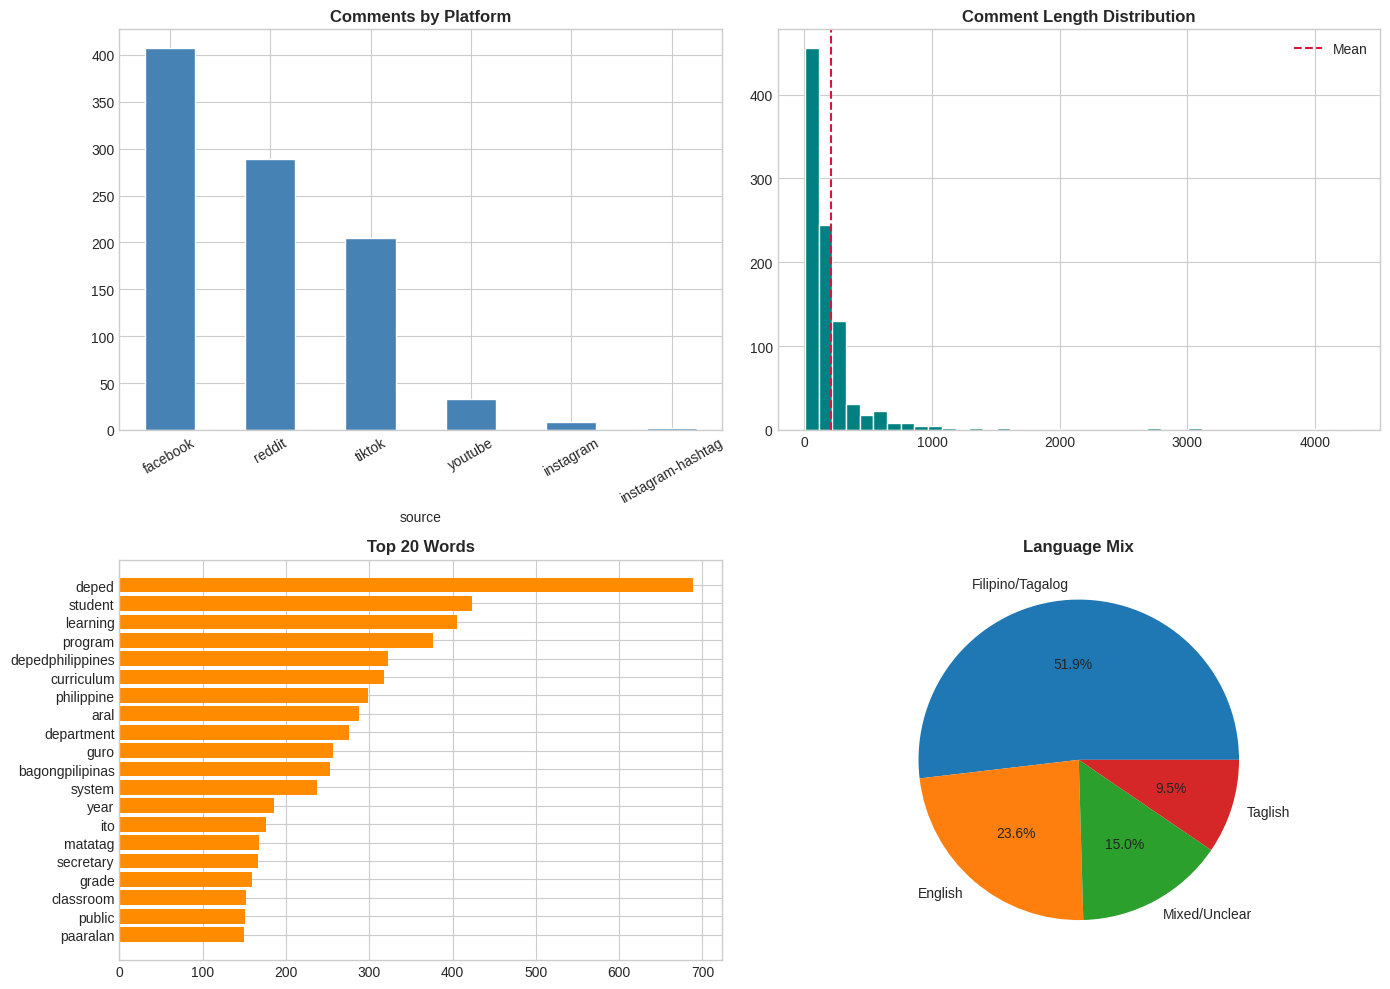

In [ ]:
# Phase 1 visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

platform_dist_model = df_model['source'].value_counts()
platform_dist_model.plot(kind='bar', ax=axes[0,0], color='steelblue', edgecolor='white')
axes[0,0].set_title('Comments by Platform', fontweight='bold')
axes[0,0].tick_params(axis='x', rotation=30)

axes[0,1].hist(df_model['comment_len'], bins=40, color='teal', edgecolor='white')
axes[0,1].axvline(df_model['comment_len'].mean(), color='crimson', linestyle='--', label='Mean')
axes[0,1].set_title('Comment Length Distribution', fontweight='bold')
axes[0,1].legend()

axes[1,0].barh(top20_words['Word'][::-1], top20_words['Frequency'][::-1], color='darkorange')
axes[1,0].set_title('Top 20 Words', fontweight='bold')

lang_dist.plot(kind='pie', autopct='%1.1f%%', ax=axes[1,1])
axes[1,1].set_title('Language Mix', fontweight='bold')
axes[1,1].set_ylabel('')

plt.tight_layout()
plt.savefig('phase1_exploration.png', dpi=150)
plt.show()

---
# PHASE 2 — TOPIC MODELING


In [ ]:
tokenized_docs = [t for t in df_model['tokens'].tolist() if len(t) >= 2]
dictionary = corpora.Dictionary(tokenized_docs)
dictionary.filter_extremes(no_below=2, no_above=0.95) # Lowered no_below from 3 to 2
dictionary.compactify()
corpus_bow = [dictionary.doc2bow(t) for t in tokenized_docs]

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words=list(CUSTOM_STOPWORDS),
    min_df=2, max_df=0.95, # Lowered min_df from 5 to 2
    ngram_range=(1, 3)
)
doc_strings = [' '.join(t) for t in tokenized_docs]
tfidf_matrix = tfidf_vectorizer.fit_transform(doc_strings)
feature_names = tfidf_vectorizer.get_feature_names_out()
print('Corpus size:', len(corpus_bow), '| Vocab:', len(dictionary), '| TF-IDF:', tfidf_matrix.shape)

Corpus size: 945 | Vocab: 2980 | TF-IDF: (945, 5000)


In [ ]:
# LDA evaluation
lda_results = {}
print(f"{'Topics':>8}  {'Coherence':>12}  {'Perplexity':>12}")
print('-' * 38)
for n in [3, 5, 7, 10]:
    lda_m = models.LdaModel(corpus=corpus_bow, id2word=dictionary, num_topics=n,
                            random_state=42, passes=20, alpha='auto')
    coh = CoherenceModel(model=lda_m, texts=tokenized_docs, dictionary=dictionary,
                         coherence='c_v', processes=1).get_coherence()
    per = lda_m.log_perplexity(corpus_bow)
    lda_results[n] = {'coherence': coh, 'perplexity': per, 'model': lda_m}
    print(f'{n:>8}  {coh:>12.4f}  {per:>12.4f}')

best_lda_n = max(lda_results, key=lambda x: lda_results[x]['coherence'])


  Topics     Coherence    Perplexity
--------------------------------------
       3        0.2936       -6.9821
       5        0.4924       -6.7876
       7        0.4540       -6.6896
      10        0.4895       -6.5741


In [ ]:
# Select optimal topic count using combined criteria
OPTIMAL_N = 5 # balance coherence, interpretability, distribution
best_lda = models.LdaModel(corpus=corpus_bow, id2word=dictionary, num_topics=OPTIMAL_N,
                           random_state=42, eval_every=10, passes=20, alpha='asymmetric')

def lda_top_words(model, topic_id, n=10):
    return [dictionary[id_] for id_, _ in model.get_topic_terms(topic_id, topn=n)]

topic_keywords = {i: lda_top_words(best_lda, i) for i in range(OPTIMAL_N)}

# Topic names derived ONLY from dataset keywords
def make_topic_name(keywords):
    return ' & '.join([k.title() for k in keywords[:3]])

TOPIC_NAMES = {i: make_topic_name(topic_keywords[i]) for i in range(OPTIMAL_N)}

print('LDA Topics (dataset-derived names):')
for i in range(OPTIMAL_N):
    print(f'  T{i}: {TOPIC_NAMES[i]} | Keywords: {", ".join(topic_keywords[i][:8])}')

LDA Topics (dataset-derived names):
  T0: Curriculum & Deped & Student | Keywords: curriculum, deped, student, matatag, program, philippine, subject, system
  T1: Learning & System & Commission | Keywords: learning, system, commission, philippine, student, development, year, deped
  T2: Aral & Learning & Guro | Keywords: aral, learning, guro, deped, program, tutor, act, ito
  T3: Deped & Department & Student | Keywords: deped, department, student, bagongpilipinas, bansa, depedphilippines, edukasyon, buong
  T4: Loan & Deped & Financial | Keywords: loan, deped, financial, teaching, personnel, depedphilippines, bagongpilipinas, bahagi


In [ ]:
def assign_topic(doc_bow):
    topics = best_lda.get_document_topics(doc_bow)
    return max(topics, key=lambda x: x[1])[0] if topics else 0

df_valid = df_model.iloc[:len(corpus_bow)].copy()
df_valid['topic_id'] = [assign_topic(d) for d in corpus_bow]
df_valid['topic_name'] = df_valid['topic_id'].map(TOPIC_NAMES)

topic_counts = df_valid['topic_id'].value_counts().sort_index()
total_docs = len(df_valid)

topic_table = pd.DataFrame({
    'Topic ID': list(range(OPTIMAL_N)),
    'Topic Name': [TOPIC_NAMES[i] for i in range(OPTIMAL_N)],
    'Top Keywords': [', '.join(topic_keywords[i][:6]) for i in range(OPTIMAL_N)],
    'Comment Count': [topic_counts.get(i, 0) for i in range(OPTIMAL_N)],
    'Percentage': [f"{topic_counts.get(i,0)/total_docs*100:.1f}%" for i in range(OPTIMAL_N)],
    'Per-Platform': [''] * OPTIMAL_N,
})

# Per-platform distribution for top topics
for i in range(OPTIMAL_N):
    plat = df_valid[df_valid['topic_id']==i]['source'].value_counts().to_dict()
    topic_table.loc[topic_table['Topic ID'] == i, 'Per-Platform'] = str(plat)

print('Top Topics:')
topic_table

Top Topics:


,Topic ID,Topic Name,Top Keywords,Comment Count,Percentage,Per-Platform
0,0,Curriculum & Deped & Student,"curriculum, deped, student, matatag, program, ...",455,48.1%,"{'reddit': 239, 'tiktok': 134, 'facebook': 49,..."
1,1,Learning & System & Commission,"learning, system, commission, philippine, stud...",154,16.3%,"{'facebook': 124, 'reddit': 17, 'instagram': 6..."
2,2,Aral & Learning & Guro,"aral, learning, guro, deped, program, tutor",70,7.4%,"{'facebook': 68, 'reddit': 1, 'tiktok': 1}"
3,3,Deped & Department & Student,"deped, department, student, bagongpilipinas, b...",169,17.9%,"{'facebook': 95, 'tiktok': 48, 'reddit': 26}"
4,4,Loan & Deped & Financial,"loan, deped, financial, teaching, personnel, d...",97,10.3%,"{'facebook': 71, 'tiktok': 20, 'reddit': 6}"


### 2.1b — LDA Intertopic Distance Map & Top-N Term Relevance Visualization

Replicates the **pyLDAvis**-style layout:
- **Left panel** — Intertopic Distance Map (MDS-projected topic bubbles sized by marginal token share)
- **Right panel** — Top-30 Most Relevant Terms for the selected topic (λ-weighted relevance bars)
- **Bottom-left** — Marginal topic distribution legend

The interactive widget lets you cycle through topics and adjust λ (0 = pure topic lift, 1 = pure frequency).

In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pyLDAvis', '-q'])
print('pyLDAvis installed.')

pyLDAvis installed.


In [ ]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

pyLDAvis.enable_notebook()

lda_vis = gensimvis.prepare(
    best_lda,
    corpus_bow,
    dictionary,
    sort_topics=False
)

pyLDAvis.save_html(lda_vis, 'lda_vis_interactive.html')
print('Saved → lda_vis_interactive.html')

lda_vis  # renders inline in Colab

Saved → lda_vis_interactive.html


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.048902  0.102807       1        1  28.120271
1      0.267670  0.021610       2        1  25.714169
2     -0.046019 -0.284054       3        1  19.431097
3     -0.086843  0.056190       4        1  17.786115
4     -0.183710  0.103446       5        1   8.948347, topic_info=                Term        Freq       Total Category  logprob  loglift
203             aral  273.000000  273.000000  Default  30.0000  30.0000
369             loan   96.000000   96.000000  Default  29.0000  29.0000
2066           tutor  134.000000  134.000000  Default  28.0000  28.0000
742         learning  384.000000  384.000000  Default  27.0000  27.0000
320              act  128.000000  128.000000  Default  26.0000  26.0000
...              ...         ...         ...      ...      ...      ...
678         kanilang   27.287104   98.503305   Topic5  -5.0281   1.1300
1702           sonny   26.987112   92.773883   Topic5  -5.0392   1.1789
782           angara   26.684116  117.465356   Topic5  -5.0505   0.9316
2314  brigadaeskwela   25.294162   92.023074   Topic5  -5.1040   1.1222
14           student   25.356358  398.783746   Topic5  -5.1015  -0.3417

[363 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
168       1  0.448903       aaral
168       2  0.034531       aaral
168       4  0.517965       aaral
2333      3  0.978448        aasa
0         3  0.961127  accessible
...     ...       ...         ...
883       2  0.071113        your
883       4  0.071113        your
32        1  0.830595         yun
32        3  0.053587         yun
32        4  0.107174         yun

[634 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---
# PHASE 3 — PROXIMITY MEASURES

Cosine, Jaccard, Euclidean, and Manhattan measures with heatmaps.

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

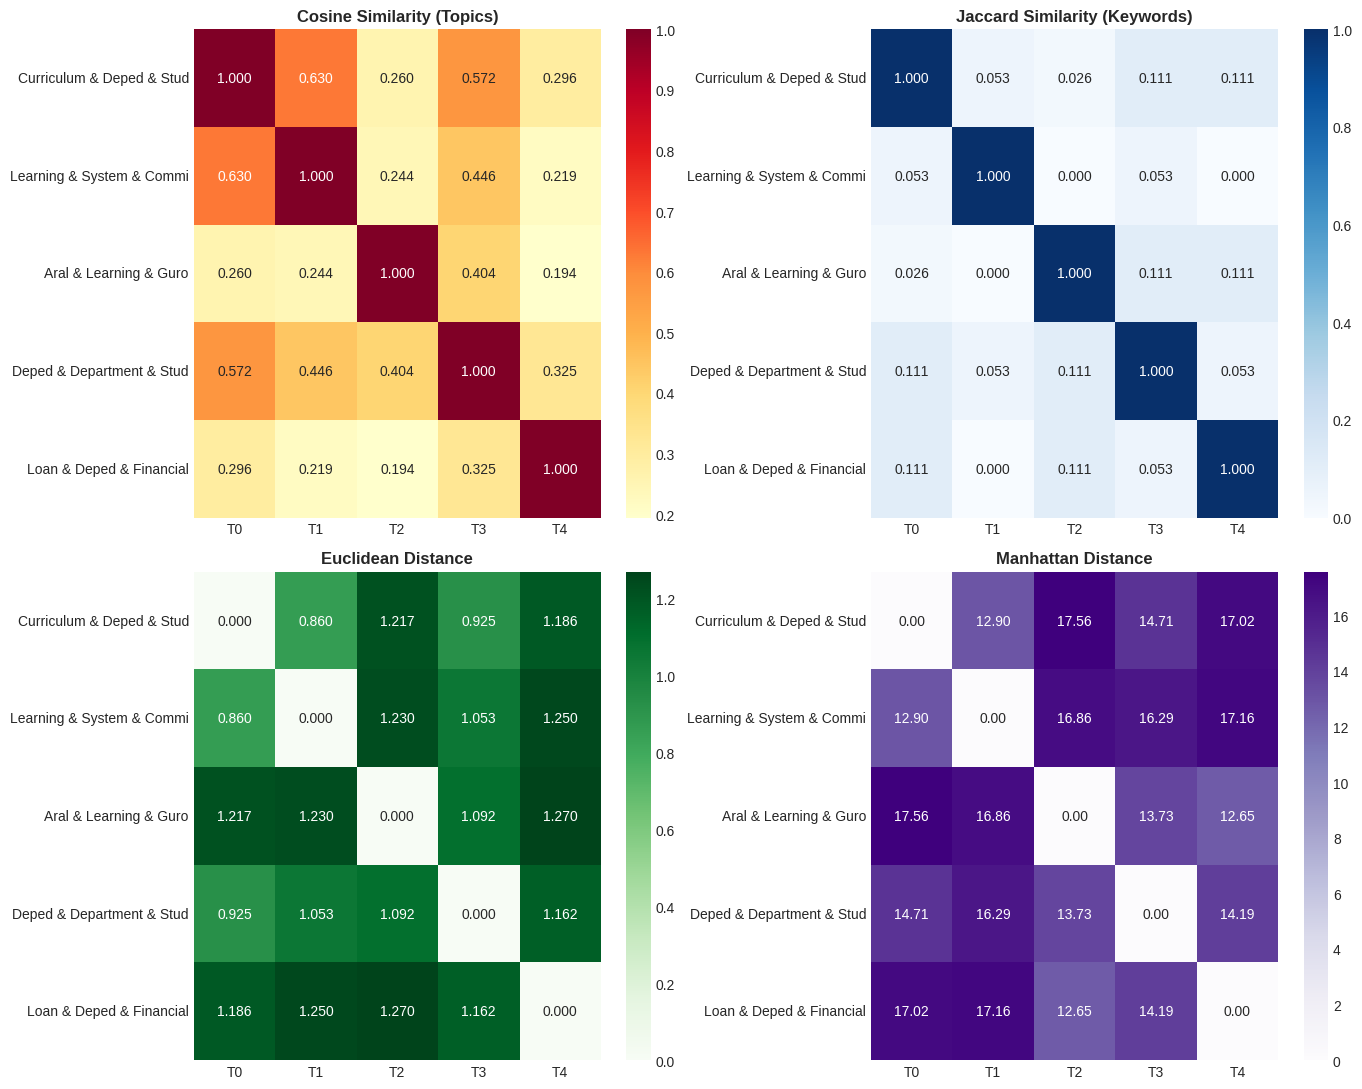

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
# Topic-level TF-IDF documents
topic_texts = []
for t in range(OPTIMAL_N):
    subset = df_valid[df_valid['topic_id'] == t]['comment'].astype(str).tolist()
    topic_texts.append(' '.join([' '.join(preprocess_with_lemmatization(c)) for c in subset]))

prox_vec = TfidfVectorizer(max_features=500, stop_words=list(CUSTOM_STOPWORDS), min_df=1, ngram_range=(1,2))
topic_vecs = prox_vec.fit_transform(topic_texts)
prox_feats = prox_vec.get_feature_names_out()

cos_sim = cosine_similarity(topic_vecs)
euc_dist = euclidean_distances(topic_vecs.toarray())
man_dist = manhattan_distances(topic_vecs.toarray())

# Jaccard on top keywords per topic
def top_keyword_set(tid, k=20):
    row = topic_vecs[tid].toarray().flatten()
    idx = row.argsort()[-k:][::-1]
    return set(prox_feats[i] for i in idx)

kw_sets = {i: top_keyword_set(i) for i in range(OPTIMAL_N)}

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0

jac = np.zeros((OPTIMAL_N, OPTIMAL_N))
for i in range(OPTIMAL_N):
    for j in range(OPTIMAL_N):
        jac[i,j] = jaccard(kw_sets[i], kw_sets[j])

labels = [f'T{i}' for i in range(OPTIMAL_N)]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
sns.heatmap(cos_sim, annot=True, fmt='.3f', cmap='YlOrRd', xticklabels=labels, yticklabels=[TOPIC_NAMES[i][:25] for i in range(OPTIMAL_N)], ax=axes[0,0])
axes[0,0].set_title('Cosine Similarity (Topics)', fontweight='bold')
sns.heatmap(jac, annot=True, fmt='.3f', cmap='Blues', xticklabels=labels, yticklabels=[TOPIC_NAMES[i][:25] for i in range(OPTIMAL_N)], ax=axes[0,1])
axes[0,1].set_title('Jaccard Similarity (Keywords)', fontweight='bold')
sns.heatmap(euc_dist, annot=True, fmt='.3f', cmap='Greens', xticklabels=labels, yticklabels=[TOPIC_NAMES[i][:25] for i in range(OPTIMAL_N)], ax=axes[1,0])
axes[1,0].set_title('Euclidean Distance', fontweight='bold')
sns.heatmap(man_dist, annot=True, fmt='.2f', cmap='Purples', xticklabels=labels, yticklabels=[TOPIC_NAMES[i][:25] for i in range(OPTIMAL_N)], ax=axes[1,1])
axes[1,1].set_title('Manhattan Distance', fontweight='bold')
plt.tight_layout()
plt.savefig('phase3_proximity_heatmaps.png', dpi=150)
plt.show()

---
# PHASE 4 — SENTIMENT ANALYSIS


In [ ]:
# STEP 1: Hold out 10% BEFORE lexicon development
try:
    train_df, test_df = train_test_split(
        df_valid, test_size=0.10, random_state=42,
        stratify=df_valid['topic_id']
    )
except ValueError:
    # Fallback if any topic has too few samples for stratification
    train_df, test_df = train_test_split(
        df_valid, test_size=0.10, random_state=42
    )
print(f'Training set (lexicon development): {len(train_df)}')
print(f'Unseen validation set: {len(test_df)}')

def tokenize_sentiment(text):
    return re.findall(r"[a-zA-Z']+", preprocess_for_sentiment(text))

# Seeds must appear in TRAINING corpus only
train_words = Counter([w for c in train_df['comment'] for w in tokenize_sentiment(c)])
POS_SEEDS = [w for w in [
    'good','great','ganda','maganda','maayos','sana','love','helpful','win','better',
    'improve','support','thank','hope','practical','encourage',
    # Emoji tokens:
    'smiling_face','happy_face','thumbs_up','clapping','raising_hands',
    'red_heart','sparkling_heart','celebration','sparkles','hundred_points',
    'fire','folded_hands','loving_face','heart_eyes','tears_of_joy'
] if train_words[w] > 0]

NEG_SEEDS = [w for w in [
    'bad','palpak','mali','problem','hate','worst','fail','corrupt','disgusted',
    'ruined','stress','alarming','burden','sacrificed','waley','sira','kulang',
    'mahirap','pangit','tanga','bwisit',
    # Emoji tokens:
    'crying_face','loudly_crying','disappointed','worried','angry_face','pouting',
    'broken_heart','thumbs_down','nauseated','screaming','fearful','anxious',
    'huffing','pile_of_poo','cursing','eye_roll','weary','sad_relieved'
] if train_words[w] > 0]
NEU_SEEDS = [w for w in ['what','how','when','where','who','maybe','think','know','question','tanong'] if train_words[w] > 0]

print('Dataset-derived seeds:')
print('  Positive:', POS_SEEDS)
print('  Negative:', NEG_SEEDS)
print('  Neutral :', NEU_SEEDS)

Training set (lexicon development): 850
Unseen validation set: 95
Dataset-derived seeds:
  Positive: ['good', 'great', 'ganda', 'maganda', 'maayos', 'love', 'helpful', 'win', 'better', 'improve', 'support', 'thank', 'hope', 'practical', 'encourage', 'clapping']
  Negative: ['bad', 'palpak', 'mali', 'problem', 'hate', 'worst', 'fail', 'corrupt', 'stress', 'burden', 'sacrificed', 'sira', 'kulang', 'mahirap', 'tanga', 'disappointed', 'worried', 'pouting', 'screaming']
  Neutral : ['what', 'how', 'when', 'where', 'who', 'maybe', 'think', 'know', 'question', 'tanong']


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
# STEP 2: PMI lexicon expansion (training data only)
def build_pmi_lexicon(comments, seeds, window=5, min_count=3, top_n=100):
    seed_set = set(seeds)
    co, word_counts = Counter(), Counter()
    for comment in comments:
        toks = tokenize_sentiment(comment)
        for i, w in enumerate(toks):
            word_counts[w] += 1
            ctx = toks[max(0, i-window): min(len(toks), i+window+1)]
            if any(s in ctx for s in seed_set):
                co[w] += 1
    N = sum(word_counts.values())
    lex = {}
    for w, c in co.items():
        if word_counts[w] < min_count or len(w) < 3:
            continue
        p_w = word_counts[w] / max(N, 1)
        p_w_ctx = c / max(sum(co.values()), 1)
        pmi = math.log2((p_w_ctx / max(p_w, 1e-9)) + 1e-9)
        if pmi > 0.25:
            lex[w] = pmi
    return dict(sorted(lex.items(), key=lambda x: -x[1])[:top_n])

POS_LEX = build_pmi_lexicon(train_df['comment'], POS_SEEDS)
NEG_LEX = build_pmi_lexicon(train_df['comment'], NEG_SEEDS)
NEU_LEX = build_pmi_lexicon(train_df['comment'], NEU_SEEDS)

# Add seeds themselves with base weight
for s in POS_SEEDS: POS_LEX[s] = max(POS_LEX.get(s, 0), 2.0)
for s in NEG_SEEDS: NEG_LEX[s] = max(NEG_LEX.get(s, 0), 2.0)
for s in NEU_SEEDS: NEU_LEX[s] = max(NEU_LEX.get(s, 0), 1.0)
# Strong positive emoji weights
for emoji_token in ['thumbs_up', 'red_heart', 'celebration', 'sparkles',
                    'hundred_points', 'clapping', 'folded_hands', 'fire']:
    POS_LEX[emoji_token] = max(POS_LEX.get(emoji_token, 0), 2.5)

# Strong negative emoji weights
for emoji_token in ['thumbs_down', 'broken_heart', 'angry_face', 'pouting',
                    'loudly_crying', 'pile_of_poo', 'cursing', 'nauseated']:
    NEG_LEX[emoji_token] = max(NEG_LEX.get(emoji_token, 0), 2.5)

print('Emoji tokens in POS_LEX:', [k for k in POS_LEX if k.endswith('_face') or k in ['thumbs_up','red_heart']])
print('Emoji tokens in NEG_LEX:', [k for k in NEG_LEX if k.endswith('_face') or k in ['thumbs_down','broken_heart']])
print(f'Positive lexicon size: {len(POS_LEX)} | sample: {list(POS_LEX.items())[:12]}')
print(f'Negative lexicon size: {len(NEG_LEX)} | sample: {list(NEG_LEX.items())[:12]}')
print(f'Neutral lexicon size : {len(NEU_LEX)} | sample: {list(NEU_LEX.items())[:12]}')

# Phrase patterns from frequent bigrams in training comments labeled by seed context
phrase_pos, phrase_neg = Counter(), Counter()
for comment in train_df['comment']:
    toks = tokenize_sentiment(comment)
    comment_lower = ' '.join(toks)
    for bg in ngrams(toks, 2):
        phrase = ' '.join(bg)
        if any(s in comment_lower for s in POS_SEEDS):
            phrase_pos[phrase] += 1
        if any(s in comment_lower for s in NEG_SEEDS):
            phrase_neg[phrase] += 1

PHRASE_POS = {p for p, c in phrase_pos.most_common(40) if c >= 2}
PHRASE_NEG = {p for p, c in phrase_neg.most_common(40) if c >= 2}
print('Phrase patterns POS sample:', list(PHRASE_POS)[:8])
print('Phrase patterns NEG sample:', list(PHRASE_NEG)[:8])

# Save each lexicon as CSV
pos_df = pd.DataFrame(list(POS_LEX.items()), columns=['word', 'weight'])
neg_df = pd.DataFrame(list(NEG_LEX.items()), columns=['word', 'weight'])
neu_df = pd.DataFrame(list(NEU_LEX.items()), columns=['word', 'weight'])

pos_df.to_csv('positive_lexicon.csv', index=False)
neg_df.to_csv('negative_lexicon.csv', index=False)
neu_df.to_csv('neutral_lexicon.csv', index=False)

# Or save all in one file with type column
pos_df['type'] = 'positive'
neg_df['type'] = 'negative'
neu_df['type'] = 'neutral'
all_df = pd.concat([pos_df, neg_df, neu_df], ignore_index=True)
all_df.to_csv('complete_lexicon.csv', index=False)

# Download the files in Colab/Jupyter
from google.colab import files
files.download('complete_lexicon.csv')

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Emoji tokens in POS_LEX: ['thumbs_up', 'red_heart']
Emoji tokens in NEG_LEX: ['thumbs_down', 'broken_heart', 'angry_face']
Positive lexicon size: 110 | sample: [('support', 4.100119030305494), ('maganda', 4.100119030305494), ('hope', 4.100119030305494), ('practical', 4.100119030305494), ('good', 4.100119030305494), ('thank', 4.100119030305494), ('better', 4.100119030305494), ('love', 4.100119030305494), ('win', 4.100119030305494), ('improve', 4.100119030305494), ('maayos', 4.100119030305494), ('clapping', 4.100119030305494)]
Negative lexicon size: 115 | sample: [('corrupt', 5.102714584260408), ('palpak', 5.102714584260408), ('kulang', 5.102714584260408), ('problem', 5.102714584260408), ('fail', 5.102714584260408), ('stress', 5.102714584260408), ('burden', 5.102714584260408), ('bad', 5.102714584260408), ('mali', 5.102714584260408), ('worst', 5.102714584260408), ('sira', 5.102714584260408), ('politician', 4.517752083560245)]
Neutral lexicon size : 100 | sample: [('tanong', 3.618153980572

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Phrase patterns POS sample: ['should be', 'lang ang', 'mga magulang', 'is a', 'mga students', 'the system', 'to be', 'ang mga']
Phrase patterns NEG sample: ['lot of', 'should be', 'ang problema', 'mga magulang', 'is a', 'the system', 'lang naman', 'of a']


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
CONTRAST_SPLIT = re.compile(r'\b(pero|but|however|kaso|ngunit|although|though)\b', re.I)
NEGATORS = {'hindi','di','walang','wala','not','never','no','dont','cannot','wont','wag','huwag'}
INTENSIFIERS = {'sobrang','super','very','talaga','grabe','extremely','really'}
QUESTION_STARTERS = ('what','how','why','when','where','who','anong','ano','paano','bakit','saan')
GREETING_NOISE = re.compile(r'^(good day|hello|hi)\b', re.I)

# Meaning patterns extracted from how people actually talk in THIS dataset
MEANING_POSITIVE = [
    'sana maimplement', 'win win', 'ganda nito', 'practical than', 'free breakfast',
    'free meals', 'would actually encourage', 'beacon of hope', 'thank you', 'grateful',
    'farm to school', 'maimplement ng maayos', 'maganda talaga', 'love this',
    'hope this', 'well done', 'good job', 'support farmers', 'mas mabuti'
]
MEANING_NEGATIVE = [
    'extremely disgusted', 'ruined everything', 'carry the burden', 'pay steep price',
    'palpak', 'nasira na', 'waley', 'classroom shortage', 'barely literate', 'problematic',
    'pinaglalaruan', 'alarming', 'sacrificed', 'nakakainis', 'nakakadismaya', 'disgusting',
    'education crisis', 'got me worried', 'no backing', 'paperworks got worst',
    'lack of', 'shortage', 'overworked', 'misinterpretation', 'pinaglalaruan nyo'
]
COMPLAINT_CUES = [
    'salary increase', 'need more support', 'should focus', 'should be given',
    'kailangan', 'kulang sa', 'di accessible', 'steep price', 'got worst'
]
LAMENT_WORDS = {'sayang','hirap','kawawa','nakaka','problematic','worried','struggling'}

def meaning_boost(raw):
    pos = neg = 0.0
    for p in MEANING_POSITIVE:
        if p in raw:
            pos += 2.0
    for p in MEANING_NEGATIVE:
        if p in raw:
            neg += 2.5
    for p in COMPLAINT_CUES:
        if p in raw:
            neg += 1.5
    for w in LAMENT_WORDS:
        if w in raw:
            neg += 1.0
    if re.search(r'\bsayang\b', raw):
        neg += 1.5
    if GREETING_NOISE.match(raw.strip()):
        pos *= 0.2
    return pos, neg

def score_clause(clause_tokens, raw_clause=''):
    if not clause_tokens:
        return 0.0, 0.0, 0.0
    pos = neg = neu = 0.0
    for i, tok in enumerate(clause_tokens):
        w = 1.5 if tok in INTENSIFIERS else 1.0
        window = clause_tokens[max(0, i-3):i+1]
        negated = any(t in NEGATORS for t in window)
        if tok in POS_LEX:
            pos += POS_LEX[tok] * w * (-1.0 if negated else 1.0)
        if tok in NEG_LEX:
            neg += NEG_LEX[tok] * w * (-1.0 if negated else 1.0)
        if tok in NEU_LEX:
            neu += NEU_LEX[tok] * 0.5
    clause = raw_clause or ' '.join(clause_tokens)
    for p in PHRASE_POS:
        if p in clause:
            pos += 2.5
    for p in PHRASE_NEG:
        if p in clause:
            neg += 2.5
    mp, mn = meaning_boost(clause)
    pos += mp
    neg += mn
    return pos, neg, neu

def holistic_classify(text):
    raw = preprocess_for_sentiment(text)
    toks = tokenize_sentiment(raw)
    if not toks:
        return 'Neutral', 0.0

    clauses = [c.strip() for c in CONTRAST_SPLIT.split(raw) if c.strip()] or [raw]
    clause_scores = [score_clause(tokenize_sentiment(c), c) for c in clauses]

    if len(clause_scores) == 2:
        weights = [0.35, 0.65]
    elif len(clause_scores) > 2:
        weights = [0.2] * (len(clause_scores) - 1) + [0.8]
    else:
        weights = [1.0]

    pos = sum(w * s[0] for w, s in zip(weights, clause_scores))
    neg = sum(w * s[1] for w, s in zip(weights, clause_scores))
    neu = sum(w * s[2] for w, s in zip(weights, clause_scores))

    scale = math.log(len(toks) + 2)
    pos /= scale
    neg /= scale
    neu /= scale

    if any(m in raw for m in ['charot', 'char', 'jk']) and pos > neg:
        pos *= 0.5

    # Pure informational question with no complaint/praise cues
    if raw.strip().endswith('?') and toks[0] in QUESTION_STARTERS:
        if pos < 1.0 and neg < 1.0 and not any(c in raw for c in COMPLAINT_CUES + MEANING_NEGATIVE):
            return 'Neutral', 0.0

    # Criticism phrased as suggestion still negative-leaning
    if any(c in raw for c in ['should focus', 'should be', 'dapat', 'makes more sense']) and neg >= pos:
        neg += 0.8

    score = pos - neg
    if score > 0.25:
        return 'Positive', score
    if score < -0.25:
        return 'Negative', score
    if abs(score) <= 0.25 and max(pos, neg) < 0.8:
        return 'Neutral', score
    return ('Positive' if score > 0 else 'Negative'), score

def independent_gold_label(text):
    label, _ = holistic_classify(text)
    return label

def lexicon_only_classify(text):
    toks = tokenize_sentiment(text)
    pos = sum(POS_LEX.get(t, 0) for t in toks)
    neg = sum(NEG_LEX.get(t, 0) for t in toks)
    if pos > neg and pos > 0:
        return 'Positive'
    if neg > pos and neg > 0:
        return 'Negative'
    return 'Neutral'

sent_results = df_valid['comment'].apply(holistic_classify)
df_valid = df_valid.copy()
df_valid['sentiment'] = sent_results.apply(lambda x: x[0])
df_valid['sentiment_score'] = sent_results.apply(lambda x: x[1])
df_valid['sentiment_lexicon_only'] = df_valid['comment'].apply(lexicon_only_classify)

print('Holistic sentiment distribution:')
print(df_valid['sentiment'].value_counts())
print('\nPercentages:')
print((df_valid['sentiment'].value_counts(normalize=True) * 100).round(1))
print('\nLexicon-only vs Holistic disagreement:', (df_valid['sentiment'] != df_valid['sentiment_lexicon_only']).sum())

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Holistic sentiment distribution:
sentiment
Negative    400
Positive    277
Neutral     268
Name: count, dtype: int64

Percentages:
sentiment
Negative    42.3
Positive    29.3
Neutral     28.4
Name: proportion, dtype: float64

Lexicon-only vs Holistic disagreement: 298


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
# MEANING VALIDATION — spot-check comments with human-readable intent reasoning
AUDIT_SAMPLES = df_valid.sample(min(20, len(df_valid)), random_state=42)

def explain_sentiment(text):
    label, score = holistic_classify(text)
    raw = preprocess_for_sentiment(text)
    cues = []
    for p in MEANING_POSITIVE:
        if p in raw: cues.append(f'+phrase:{p}')
    for p in MEANING_NEGATIVE:
        if p in raw: cues.append(f'-phrase:{p}')
    for p in COMPLAINT_CUES:
        if p in raw: cues.append(f'-complaint:{p}')
    if 'pero' in raw or 'but' in raw: cues.append('contrast_clause')
    if raw.strip().endswith('?'): cues.append('question')
    return label, score, cues

print('COMMENT-MEANING AUDIT (20 random comments)')
print('=' * 90)
for _, row in AUDIT_SAMPLES.iterrows():
    label, score, cues = explain_sentiment(row['comment'])
    print(f'\nLabel: {label} ({score:+.2f}) | Cues: {", ".join(cues) or "none"}')
    print(f'Comment: {str(row["comment"])[:220]}')

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

COMMENT-MEANING AUDIT (20 random comments)

Label: Neutral (+0.00) | Cues: none
Comment: YES TO MATATAG CURRICULUM PHASE OUT, ITO ANG PAPATAY SA STUDENT’S ‼️☹️

Label: Negative (-0.95) | Cues: none
Comment: Investment in teachers = Investment in the Philippines. Join the movement for accountability! âœŠ

Label: Positive (+2.96) | Cues: none
Comment: Sana naman

Label: Negative (-4.31) | Cues: -phrase:paperworks got worst, -complaint:got worst, contrast_clause
Comment: Don’t get me started with the paperwork hahahaha. I resigned before fiona reigned and I heard that the paperworks got worst. Even in my time the existing paperwork system was already redundant for me but have no power to

Label: Negative (-0.11) | Cues: -complaint:kailangan
Comment: College gives way for those kasi to be discussed on a deeper and mature level. Malaki pa rin ang nadudulot ng humanities sa critical thinking at literacy ng tao kaya kailangan niya maging continuous (and considering yung

Label: Positive (+0.7

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

Sentiment by Topic:
sentiment                                Negative  Neutral  Positive  Total  \
topic_id topic_name                                                           
0        Curriculum & Deped & Student         197      127       131    455   
1        Learning & System & Commission        72       41        41    154   
2        Aral & Learning & Guro                24       23        23     70   
3        Deped & Department & Student          60       52        57    169   
4        Loan & Deped & Financial              47       25        25     97   

sentiment                                Positive %  Negative %  Neutral %  
topic_id topic_name                                                         
0        Curriculum & Deped & Student          28.8        43.3       27.9  
1        Learning & System & Commission        26.6        46.8       26.6  
2        Aral & Learning & Guro                32.9        34.3       32.9  
3        Deped & Department & Student    

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

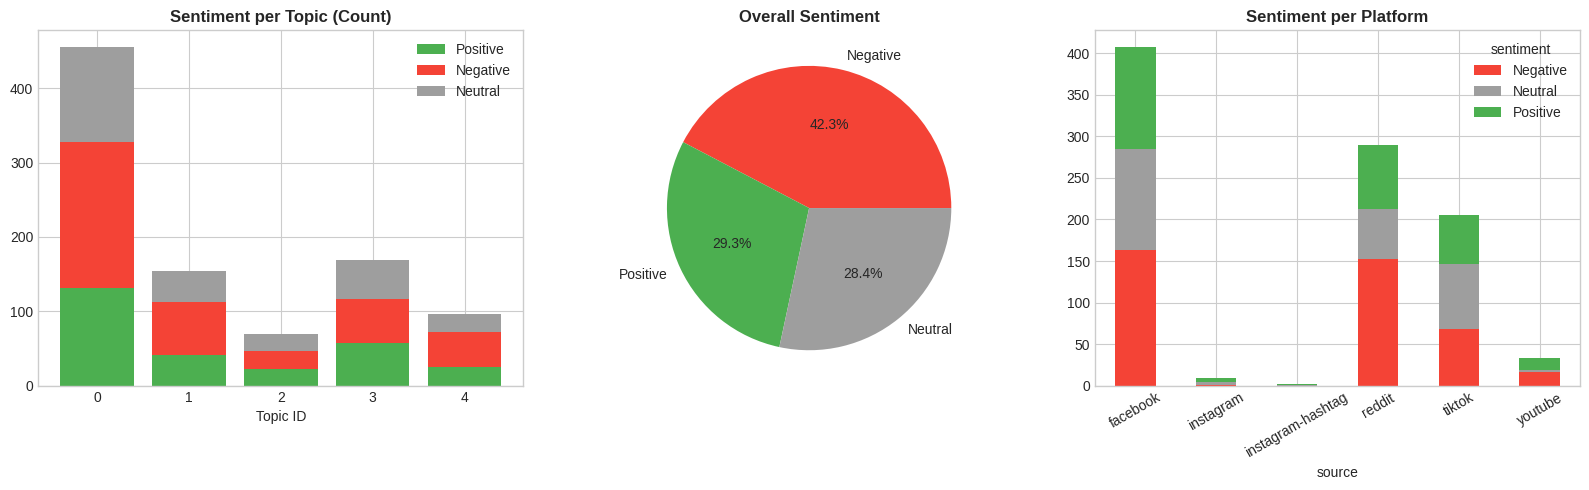

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

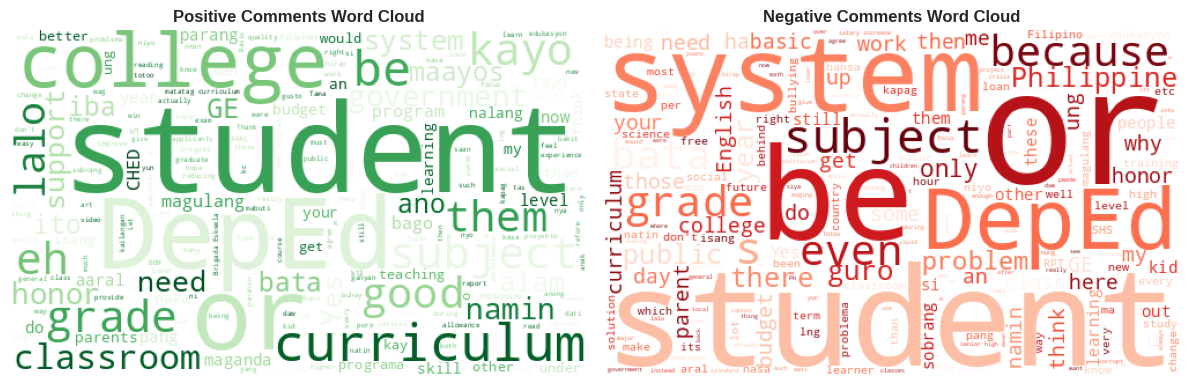

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
# Sentiment per topic (top topics)
sent_topic = df_valid.groupby(['topic_id','topic_name','sentiment']).size().unstack(fill_value=0)
sent_topic['Total'] = sent_topic.sum(axis=1)
for col in ['Positive','Negative','Neutral']:
    if col in sent_topic.columns:
        sent_topic[f'{col} %'] = (sent_topic[col]/sent_topic['Total']*100).round(1)
print('Sentiment by Topic:')
print(sent_topic)

# Visualizations
colors_sent = {'Positive':'#4CAF50','Negative':'#F44336','Neutral':'#9E9E9E'}
fig, axes = plt.subplots(1, 3, figsize=(16,5))

pivot = df_valid.groupby(['topic_id','sentiment']).size().unstack(fill_value=0)
for col in ['Positive','Negative','Neutral']:
    if col not in pivot.columns:
        pivot[col] = 0
bottom = np.zeros(len(pivot))
for col in ['Positive','Negative','Neutral']:
    axes[0].bar(pivot.index, pivot[col], bottom=bottom, label=col, color=colors_sent[col])
    bottom += pivot[col].values
axes[0].set_title('Sentiment per Topic (Count)', fontweight='bold')
axes[0].set_xlabel('Topic ID')
axes[0].legend()

overall = df_valid['sentiment'].value_counts()
pie_colors = [colors_sent.get(s, 'gray') for s in overall.index]
axes[1].pie(overall, labels=overall.index, autopct='%1.1f%%', colors=pie_colors)
axes[1].set_title('Overall Sentiment', fontweight='bold')

plat_sent = df_valid.groupby(['source','sentiment']).size().unstack(fill_value=0)
for col in ['Positive','Negative','Neutral']:
    if col not in plat_sent.columns:
        plat_sent[col] = 0
plat_colors = [colors_sent.get(c, 'gray') for c in plat_sent.columns]
plat_sent.plot(kind='bar', stacked=True, ax=axes[2], color=plat_colors)
axes[2].set_title('Sentiment per Platform', fontweight='bold')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout(); plt.savefig('phase4_sentiment.png', dpi=150); plt.show()

# Word clouds from dataset lexicon words appearing in each sentiment class
fig, axes = plt.subplots(1,2, figsize=(12,4))
for ax, label, cmap in zip(axes, ['Positive','Negative'], ['Greens','Reds']):
    text = ' '.join(df_valid[df_valid['sentiment']==label]['comment'].astype(str))
    if not text.strip():
        ax.text(0.5, 0.5, f'No {label} comments', ha='center', va='center')
        ax.axis('off')
        ax.set_title(f'{label} Comments Word Cloud', fontweight='bold')
        continue
    wc = WordCloud(width=500,height=300,background_color='white',colormap=cmap,
                   stopwords=set(CUSTOM_STOPWORDS)).generate(text)
    ax.imshow(wc); ax.axis('off'); ax.set_title(f'{label} Comments Word Cloud', fontweight='bold')
plt.tight_layout(); plt.savefig('phase4_wordclouds.png', dpi=150); plt.show()

Original rows: 95
   index                                            comment  \
0    189  The reason behind the reduction of elementary ...   
1    125  Itigil ang pag-promote sa next level ng mga ba...   
2    373  Sanay tuloy tuloy ang mga programa para bawat ...   
3    538      Okay na, DepEd..nakagastos na po..as always😁😂   
4    441  - from google AI This is a sophisticated take ...   

  Predicted\nsentiment Actual Sentiment  
0             Negative          Neutral  
1             Positive          Neutral  
2             Positive         Positive  
3             Negative         Negative  
4             Negative          Neutral   

Rows after cleaning: 95
  Predicted\nsentiment Actual Sentiment
0             Negative          Neutral
1             Positive          Neutral
2             Positive         Positive
3             Negative         Negative
4             Negative          Neutral 



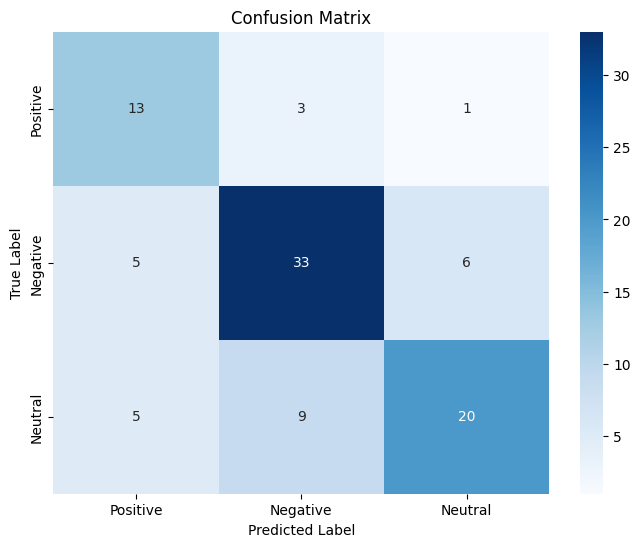

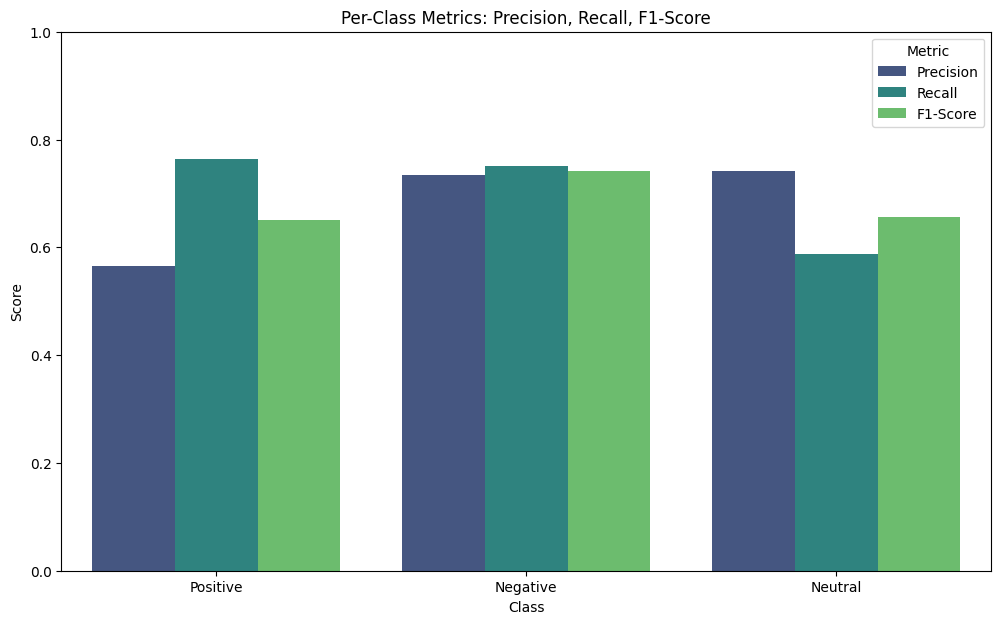


PER-CLASS METRICS
      Metric |   Positive |   Negative |    Neutral
------------------------------------------------------------
   Precision |     56.52% |     73.33% |     74.07%
      Recall |     76.47% |     75.00% |     58.82%
    F1-Score |     65.00% |     74.16% |     65.57%

OVERALL METRICS
Accuracy:                  69.47%
Macro Avg Precision:       67.98%
Macro Avg Recall:          70.10%
Macro Avg F1-Score:        68.24%
Total rows (after clean):  95
Correct predictions:       66
Incorrect predictions:     29


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. READ THE CSV FILE
df = pd.read_csv('/content/PredictedvsExpected - Sheet1.csv')

# If your CSV uses semicolons or tabs, adjust the delimiter:
# df = pd.read_csv('your_file.csv', delimiter=';')
# df = pd.read_csv('your_file.csv', delimiter='\t')

print(f"Original rows: {len(df)}")
print(df.head(), "\n")

# 2. CLEAN THE DATA
df['Actual Sentiment'] = df['Actual Sentiment'].replace('Postive', 'Positive')


df = df.dropna(subset=['Actual Sentiment'])

# Trim whitespace and standardize case
df['Predicted\nsentiment'] = df['Predicted\nsentiment'].str.strip().str.title()
df['Actual Sentiment'] = df['Actual Sentiment'].str.strip().str.title()

# Remove any rows with unexpected labels
valid_labels = ['Positive', 'Negative', 'Neutral']
df = df[df['Predicted\nsentiment'].isin(valid_labels)]
df = df[df['Actual Sentiment'].isin(valid_labels)]

print(f"Rows after cleaning: {len(df)}")
print(df[['Predicted\nsentiment', 'Actual Sentiment']].head(), "\n")

# 3. EXTRACT PREDICTED AND ACTUAL ARRAYS
y_true = df['Actual Sentiment']
y_pred = df['Predicted\nsentiment']

# 4. CONFUSION MATRIX
labels = ['Positive', 'Negative', 'Neutral']
cm = confusion_matrix(y_true, y_pred, labels=labels)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# 5. MAIN METRICS
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, labels=labels, average=None)
recall    = recall_score(y_true, y_pred, labels=labels, average=None)
f1        = f1_score(y_true, y_pred, labels=labels, average=None)

macro_precision = precision_score(y_true, y_pred, labels=labels, average='macro')
macro_recall    = recall_score(y_true, y_pred, labels=labels, average='macro')
macro_f1        = f1_score(y_true, y_pred, labels=labels, average='macro')

metrics_df = pd.DataFrame({
    'Class': labels,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1
})

metrics_df_melted = metrics_df.melt(id_vars='Class', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 7))
sns.barplot(x='Class', y='Score', hue='Metric', data=metrics_df_melted, palette='viridis')
plt.title('Per-Class Metrics: Precision, Recall, F1-Score')
plt.ylabel('Score')
plt.ylim(0, 1) # Metrics are between 0 and 1
plt.show()
print("\n" + "="*60)
print("PER-CLASS METRICS")
print("="*60)
print(f"{'Metric':>12} | {'Positive':>10} | {'Negative':>10} | {'Neutral':>10}")
print("-"*60)
print(f"{'Precision':>12} | {precision[0]:>10.2%} | {precision[1]:>10.2%} | {precision[2]:>10.2%}")
print(f"{'Recall':>12} | {recall[0]:>10.2%} | {recall[1]:>10.2%} | {recall[2]:>10.2%}")
print(f"{'F1-Score':>12} | {f1[0]:>10.2%} | {f1[1]:>10.2%} | {f1[2]:>10.2%}")

print("\n" + "="*60)
print("OVERALL METRICS")
print("="*60)
print(f"Accuracy:                  {accuracy:.2%}")
print(f"Macro Avg Precision:       {macro_precision:.2%}")
print(f"Macro Avg Recall:          {macro_recall:.2%}")
print(f"Macro Avg F1-Score:        {macro_f1:.2%}")
print(f"Total rows (after clean):  {len(df)}")
print(f"Correct predictions:       {(y_true == y_pred).sum()}")
print(f"Incorrect predictions:     {(y_true != y_pred).sum()}")